# SmartCheck – Gatecheck Weekly Report: RBPL vs FCPL
Covers **Visitors and Vendors** for both branches, then a **side-by-side comparison**.

In [25]:
# ---- CELL 1: imports ----
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 13, 'axes.titleweight': 'bold', 'font.size': 10})
COLORS = {'Visitors': '#1f4e79', 'Vendors': '#2e9c8f'}
BRANCH_COLORS = {'RBPL': '#1f4e79', 'FCPL': '#e08a1e'}

In [26]:
# ---- CELL 2: SETTINGS 
BRANCHES = {
    'RBPL': {
        'Visitors': r'C:\Users\Moses\Downloads\VisitorExcel_2026_11_9_9_16_32_213.xlsx',
        'Vendors':  r'C:\Users\Moses\Downloads\VisitorExcel_2026_11_9_9_18_7_322.xlsx',
    },
    'FCPL': {
        'Visitors': r'C:\Users\Moses\Downloads\VisitorExcel_2026_11_9_9_10_57_407.xlsx',
        'Vendors':  r'C:\Users\Moses\Downloads\VisitorExcel_2026_11_9_9_11_39_999.xlsx',
    },
}
OUTPUT_ROOT = 'gatecheck_output'      # a sub-folder per branch + the comparison file are saved here
LONG_STAY_HOURS = 4                   # stays longer than this are flagged
os.makedirs(OUTPUT_ROOT, exist_ok=True)

## 1. Loader & cleaner

In [27]:
# ---- CELL 3: loader + cleaner 
DT_FMT = '%d-%m-%Y %I:%M %p'

EXPECTED_COLS = ['SNO', 'Name', 'Email', 'Mobile', 'Person To Meet', 'Purpose of Meet', 'Category', 'Govt ID', 'Type', 'Access Card',
                 'Belongings/ Tools/ Remarks', 'Coming From', 'From Address', 'Persons(+)', 'Vehicle Type', 'Vehicle No', 'Parking Slot', 'TimeIn', 'TimeOut']
def _norm(s): return re.sub(r'[^a-z0-9]', '', str(s).lower())
def harmonise_columns(df, kind):
    """Tolerate small header differences in SmartCheck exports (spaces, case, 'Persons (+)' vs 'Persons(+)').
    Any expected column that is genuinely absent is created empty, with a warning listing what the file does contain."""
    lookup = {_norm(c): c for c in EXPECTED_COLS}; lookup['persons'] = 'Persons(+)'
    df = df.rename(columns={c: lookup.get(_norm(c), c) for c in df.columns})
    df = df.loc[:, ~df.columns.duplicated()]
    missing = [c for c in EXPECTED_COLS if c not in df.columns]
    if missing:
        print(f'⚠ {kind}: column(s) not found in this export -> {missing}. Columns present: {list(df.columns)}')
        for c in missing: df[c] = np.nan
    return df

def load_gate(path, kind):
    """Read a SmartCheck gate-entry export. Returns (df, period_text) or (None, None) if file missing/empty."""
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print(f'⚠ {kind}: file missing or empty -> skipped ({path})'); return None, None
    raw = pd.read_excel(path, header=None)
    period = str(raw.iloc[1, 0])      # row 1 holds the date range, e.g. '02-11-2026 12:00 AM to 07-11-2026 12:00 AM'
    hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq('SNO')]
    if len(hdr) == 0:
        print(f'⚠ {kind}: header row (SNO) not found -> skipped'); return None, None
    df = raw.iloc[hdr[0] + 1:].copy(); df.columns = raw.iloc[hdr[0]].astype(str).str.strip()
    df = harmonise_columns(df, kind)
    df = df[pd.to_numeric(df['SNO'], errors='coerce').notna()].reset_index(drop=True)
    if df.empty:
        print(f'ℹ {kind}: no records this week'); return None, period
    return clean_gate(df, kind), period

def clean_gate(df, kind):
    df = df.copy()
    for c in df.select_dtypes(include=['object','string']): df[c] = df[c].astype(str).str.strip().replace({'-': np.nan, 'nan': np.nan, '': np.nan, 'None': np.nan})
    df['Group'] = kind
    df['TimeIn']  = pd.to_datetime(df['TimeIn'],  format=DT_FMT, errors='coerce')
    df['TimeOut'] = pd.to_datetime(df['TimeOut'], format=DT_FMT, errors='coerce')
    df['Date'] = df['TimeIn'].dt.normalize(); df['Day'] = df['TimeIn'].dt.day_name(); df['Hour'] = df['TimeIn'].dt.hour
    df['StayMins'] = (df['TimeOut'] - df['TimeIn']).dt.total_seconds() / 60
    df.loc[df['StayMins'] < 0, 'StayMins'] = np.nan
    df['StillInside'] = df['TimeOut'].isna()
    df['Persons(+)'] = pd.to_numeric(df['Persons(+)'], errors='coerce').fillna(0).astype(int)
    df['Headcount'] = 1 + df['Persons(+)']                       # the visitor + people accompanying
    df['NameKey'] = df['Name'].str.lower().str.replace(r'[^a-z ]', '', regex=True).str.strip()
    # Host company = text in last brackets of 'Person To Meet'  e.g. "Femi (Greenwich Merchant Bank )"
    df['HostCompany'] = df['Person To Meet'].str.extract(r'\(([^()]*)\)\s*$')[0].str.strip()
    df['HostPerson']  = df['Person To Meet'].str.replace(r'\([^()]*\)\s*$', '', regex=True).str.strip()
    df['Category']    = df['Category'].str.title()
    df['Purpose of Meet'] = df['Purpose of Meet'].str.title()
    df['Belongings']  = df['Belongings/ Tools/ Remarks'].str.lower()
    df['HasLaptop']   = df['Belongings'].str.contains('laptop|ipad|macbook', na=False)
    df['HasVehicle']  = df['Vehicle Type'].notna()
    df['GovtIDCaptured'] = df['Govt ID'].str.contains(r'\d', na=False)   # 'Aadhar -' with no number = not captured
    # Bulk sign-out: 4+ people signed out in the same minute (security clearing the gate at closing) -> stay time is overstated
    df['BulkSignOut'] = df.groupby('TimeOut')['TimeOut'].transform('size').ge(4) & df['TimeOut'].notna()
    return df

## 2. Analysis for one branch (runs automatically for each branch below)


In [28]:
def analyse(BRANCH):
    """Runs the full gatecheck analysis for one branch."""
    FILES = BRANCHES[BRANCH]
    OUTPUT_DIR = f'{OUTPUT_ROOT}/{BRANCH}'; os.makedirs(OUTPUT_DIR, exist_ok=True)
    print('=' * 70); print(f'  {BRANCH}'); print('=' * 70)
    frames, periods = {}, {}
    for kind, path in FILES.items():
        d, p = load_gate(path, kind)
        if d is not None: frames[kind] = d
        if p: periods[kind] = p

    if not frames:
        print(f'⚠ {BRANCH}: no data loaded – check the file paths in Cell 2'); return None
    ALL = pd.concat(frames.values(), ignore_index=True)
    print('Report period (from SmartCheck):', sorted(set(periods.values())))
    if len(set(periods.values())) > 1: print('⚠ The Visitors and Vendors files cover DIFFERENT date ranges -> check the file paths in Cell 2.')
    print({k: len(v) for k, v in frames.items()}, '| total records:', len(ALL))

    print('\n--- Coverage check ---')
    cov = ALL.groupby('Group')['Date'].agg(['min', 'max', 'nunique']).rename(columns={'nunique': 'days_with_data'})
    print(cov)
    week_start = ALL['Date'].min() - pd.Timedelta(days=ALL['Date'].min().weekday())
    expected = pd.date_range(week_start, periods=5)
    missing_days = [d.strftime('%a %d-%b') for d in expected if d not in set(ALL['Date'])]
    if missing_days: print('\n⚠ No records on:', ', '.join(missing_days), '-> check your export date range (end date should be the Saturday).')
    else: print('\n✔ All five working days (Mon–Fri) are present.')

    print('\n--- 1. Headline numbers ---')
    def kpis(d):
        return pd.Series({
            'Entries (records)': len(d),
            'Unique people': d['NameKey'].nunique(),
            'Total headcount (incl. accompanying)': int(d['Headcount'].sum()),
            'Avg stay (mins)': round(d['StayMins'].mean(), 0),
            'Median stay (mins)': round(d['StayMins'].median(), 0),
            f'Stays > {LONG_STAY_HOURS} hrs': int((d['StayMins'] > LONG_STAY_HOURS * 60).sum()),
            'Bulk sign-outs (stay time unreliable)': int(d['BulkSignOut'].sum()),
            'Not signed out': int(d['StillInside'].sum()),
            'With laptop/iPad declared': int(d['HasLaptop'].sum()),
            'Arrived with vehicle': int(d['HasVehicle'].sum()),
        })
    summary = pd.concat({k: kpis(v) for k, v in frames.items()}, axis=1)
    summary['All'] = kpis(ALL)
    display(summary)

    print('\n--- 2. Daily traffic ---')
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
    daily = ALL.pivot_table(index='Day', columns='Group', values='SNO', aggfunc='count', fill_value=0).reindex(day_order).fillna(0).astype(int)
    daily['Total'] = daily.sum(axis=1)
    display(daily)
    ax = daily.drop(columns='Total').plot(kind='bar', stacked=True, color=[COLORS[c] for c in daily.columns[:-1]], rot=0)
    for i, t in enumerate(daily['Total']): ax.text(i, t + 0.5, str(t), ha='center', fontweight='bold')
    ax.set_title(f'{BRANCH}: Gate entries per day'); ax.set_xlabel(''); ax.set_ylabel('Entries'); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/01_daily_entries.png', dpi=150); plt.show()
    busiest = daily['Total'].idxmax(); print(f'Busiest day: {busiest} ({daily.loc[busiest, "Total"]} entries); quietest: {daily[daily.Total>0]["Total"].idxmin()}')

    print('\n--- 3. Peak hours ---')
    hourly = ALL.groupby('Hour').size().reindex(range(7, 19), fill_value=0)
    ax = hourly.plot(kind='bar', color=COLORS['Visitors'], rot=0)
    ax.set_xticklabels([f'{h}:00' for h in hourly.index]); ax.set_title(f'{BRANCH}: Arrivals by hour of day'); ax.set_xlabel(''); ax.set_ylabel('Arrivals')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/02_hourly_arrivals.png', dpi=150); plt.show()
    pk = hourly.idxmax(); print(f'Peak hour: {pk}:00–{pk+1}:00 ({hourly.max()} arrivals, {hourly.max()/hourly.sum():.0%} of all entries)')
    heat = ALL.pivot_table(index='Day', columns='Hour', values='SNO', aggfunc='count', fill_value=0).reindex(day_order).fillna(0)
    display(heat)

    print('\n--- 4. Host companies ---')
    hosts = ALL.groupby(['HostCompany', 'Group']).size().unstack(fill_value=0)
    hosts['Total'] = hosts.sum(axis=1); hosts = hosts.sort_values('Total', ascending=False)
    display(hosts.head(10))
    top = hosts.head(8).drop(columns='Total')[::-1]
    ax = top.plot(kind='barh', stacked=True, color=[COLORS[c] for c in top.columns])
    ax.set_title(f'{BRANCH}: Most-visited host companies'); ax.set_ylabel('')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/03_host_companies.png', dpi=150); plt.show()
    print(f'{hosts.index[0]} received {hosts.iloc[0]["Total"]/len(ALL):.0%} of all entries.  Entries with no host company recorded: {ALL.HostCompany.isna().sum()}')

    print('\n--- 5. Purpose & check-in method ---')
    purpose = ALL['Purpose of Meet'].fillna('Not recorded').value_counts()
    method = ALL.groupby(['Type', 'Group']).size().unstack(fill_value=0); method['Total'] = method.sum(axis=1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    purpose.plot(kind='barh', ax=ax[0], color=COLORS['Visitors']).invert_yaxis(); ax[0].set_title('Purpose of visit')
    mt = method['Total'].sort_values(); mt.plot(kind='barh', ax=ax[1], color=COLORS['Vendors']); ax[1].set_title('Check-in method'); ax[1].set_ylabel('')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/04_purpose_method.png', dpi=150); plt.show()
    display(method.sort_values('Total', ascending=False))
    walk = (ALL['Type'].str.lower() == 'walk-in').mean()
    print(f'Walk-ins (not pre-registered): {walk:.0%} of entries | Purpose not recorded: {ALL["Purpose of Meet"].isna().mean():.0%}')

    print('\n--- 6. Time on premises ---')
    stay = ALL.dropna(subset=['StayMins'])
    bulk = int(ALL['BulkSignOut'].sum())
    print(f'ℹ {bulk} entries ({bulk/len(ALL):.0%}) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.')
    print('All entries:'); print(stay.groupby('Group')['StayMins'].describe()[['count', 'mean', '50%', 'max']].round(0).rename(columns={'50%': 'median'}))
    fig, ax = plt.subplots()
    bins = [0, 15, 30, 60, 120, 240, 600]; labels = ['<15m', '15–30m', '30–60m', '1–2h', '2–4h', '>4h']
    dist = pd.cut(stay['StayMins'], bins, labels=labels).value_counts().reindex(labels)
    dist.plot(kind='bar', ax=ax, color=COLORS['Visitors'], rot=0); ax.set_title(f'{BRANCH}: How long people stay'); ax.set_xlabel(''); ax.set_ylabel('Entries')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/05_stay_duration.png', dpi=150); plt.show()

    real = stay[~stay['BulkSignOut']]
    print('\nExcluding bulk sign-outs (more reliable):'); print(real.groupby('Group')['StayMins'].describe()[['count', 'mean', '50%', 'max']].round(0).rename(columns={'50%': 'median'}))
    long_stays = ALL[ALL['StayMins'] > LONG_STAY_HOURS * 60][['Group', 'Name', 'HostCompany', 'TimeIn', 'TimeOut', 'StayMins', 'BulkSignOut']].sort_values('StayMins', ascending=False)
    long_stays['StayMins'] = long_stays['StayMins'].round(0)
    print(f'\nStays longer than {LONG_STAY_HOURS} hrs ({int(long_stays.BulkSignOut.sum())} of {len(long_stays)} were bulk sign-outs):'); display(long_stays)

    print('\n--- 7. Exceptions for follow-up ---')
    not_out = ALL[ALL['StillInside']][['Group', 'Name', 'HostCompany', 'TimeIn']]
    repeat = (ALL.groupby('NameKey').agg(Name=('Name', 'first'), Visits=('SNO', 'count'), Days=('Date', 'nunique'), Group=('Group', 'first'))
              .query('Visits > 1').sort_values('Visits', ascending=False))
    big_groups = ALL[ALL['Persons(+)'] >= 3][['Group', 'Name', 'HostCompany', 'Persons(+)', 'TimeIn']]
    dq = pd.Series({
        'Category blank': ALL['Category'].isna().sum(),
        'Purpose of visit blank': ALL['Purpose of Meet'].isna().sum(),
        'Host company missing': ALL['HostCompany'].isna().sum(),
        'Email not captured': ALL['Email'].isna().sum(),
        'Govt ID number not captured': (~ALL['GovtIDCaptured']).sum(),
        'No sign-out time': ALL['StillInside'].sum(),
    }).to_frame('Records'); dq['% of entries'] = (dq['Records'] / len(ALL) * 100).round(0)

    print('Records with no sign-out time (verify they left):'); display(not_out)
    print('Repeat visitors (same name, >1 entry this week):'); display(repeat.head(10))
    print('Large groups (3+ accompanying):'); display(big_groups)
    print('Data-quality gaps:'); display(dq)

    print('\n--- 8. Talking points ---')
    best = daily['Total'].idxmax(); share = lambda g: len(frames[g]) / len(ALL) if g in frames else 0
    pts = [
        f'{BRANCH} gate recorded {len(ALL)} entries this week ({int(ALL.Headcount.sum())} people including accompanying persons): '
        + ', '.join(f'{len(v)} {k.lower()}' for k, v in frames.items()) + '.',
        f'Busiest day was {best} with {daily.loc[best, "Total"]} entries; peak arrival hour was {pk}:00–{pk+1}:00 ({hourly.max()/hourly.sum():.0%} of arrivals).',
        f'{hosts.index[0]} was the most-visited host ({hosts.iloc[0]["Total"]/len(ALL):.0%} of entries).',
        f'Typical stay was {real.StayMins.median():.0f} mins (average {real.StayMins.mean():.0f}), excluding {bulk} entries signed out in bulk at closing. {len(long_stays)} stay(s) exceeded {LONG_STAY_HOURS} hrs, {int(long_stays.BulkSignOut.sum())} of them bulk sign-outs.',
        f'{len(not_out)} record(s) had no sign-out time – security should confirm these people left.' if len(not_out) else 'Every entry has a sign-out time.',
        f'{dq.loc["Govt ID number not captured", "% of entries"]:.0f}% of entries have no government ID number captured; {dq.loc["Category blank", "Records"]} have no category and {dq.loc["Purpose of visit blank", "Records"]} have no purpose recorded.',
    ]
    for p in pts: print('•', p)

    print('\n--- 9. Export ---')
    xl = f'{OUTPUT_DIR}/Gatecheck_{BRANCH}_weekly_summary.xlsx'
    with pd.ExcelWriter(xl) as w:
        summary.to_excel(w, sheet_name='KPIs'); daily.to_excel(w, sheet_name='Daily'); heat.to_excel(w, sheet_name='Day x Hour')
        hosts.to_excel(w, sheet_name='Host companies'); long_stays.to_excel(w, sheet_name='Long stays', index=False)
        not_out.to_excel(w, sheet_name='No sign-out', index=False); repeat.to_excel(w, sheet_name='Repeat visitors')
        dq.to_excel(w, sheet_name='Data quality')
        ALL.drop(columns=['NameKey']).to_excel(w, sheet_name='Clean data', index=False)
    print('Saved:', os.path.abspath(OUTPUT_DIR)); print(*sorted(os.listdir(OUTPUT_DIR)), sep='\n  ')

    return dict(BRANCH=BRANCH, ALL=ALL, frames=frames, summary=summary, daily=daily, hourly=hourly, hosts=hosts, real=real, bulk=bulk,
                long_stays=long_stays, not_out=not_out, repeat=repeat, dq=dq, pk=pk, pts=pts, output_dir=OUTPUT_DIR)

## 3. Run RBPL and FCPL

  RBPL
⚠ Visitors: column(s) not found in this export -> ['Access Card', 'From Address', 'Persons(+)', 'Vehicle No']. Columns present: ['SNO', 'Name', 'Email', 'Mobile', 'Person To Meet', 'Purpose of Meet', 'Category', 'Govt ID', 'Type', 'Access Number', 'Belongings/ Tools/ Remarks', 'Coming From', 'Company/Area', 'Total Persons', 'Additional Person Count', 'Additional Person Details', 'Vehicle Type', 'Vehicle Number', 'Parking Slot', 'TimeIn', 'TimeOut', 'Duration', 'Approved', 'Issued']
⚠ Vendors: column(s) not found in this export -> ['Access Card', 'From Address', 'Persons(+)', 'Vehicle No']. Columns present: ['SNO', 'Name', 'Email', 'Mobile', 'Person To Meet', 'Purpose of Meet', 'Category', 'Govt ID', 'Type', 'Access Number', 'Belongings/ Tools/ Remarks', 'Coming From', 'Company/Area', 'Total Persons', 'Additional Person Count', 'Additional Person Details', 'Vehicle Type', 'Vehicle Number', 'Parking Slot', 'TimeIn', 'TimeOut', 'Duration', 'Approved', 'Issued']
Report period (from 

,Visitors,Vendors,All
Entries (records),205.0,17.0,222.0
Unique people,186.0,14.0,198.0
Total headcount (incl. accompanying),205.0,17.0,222.0
Avg stay (mins),146.0,160.0,147.0
Median stay (mins),64.0,59.0,64.0
Stays > 4 hrs,45.0,6.0,51.0
Bulk sign-outs (stay time unreliable),45.0,0.0,45.0
Not signed out,2.0,0.0,2.0
With laptop/iPad declared,20.0,1.0,21.0
Arrived with vehicle,3.0,1.0,4.0



--- 2. Daily traffic ---


Group,Vendors,Visitors,Total
Day,,,
Monday,4,49,53
Tuesday,4,52,56
Wednesday,5,38,43
Thursday,2,27,29
Friday,2,39,41


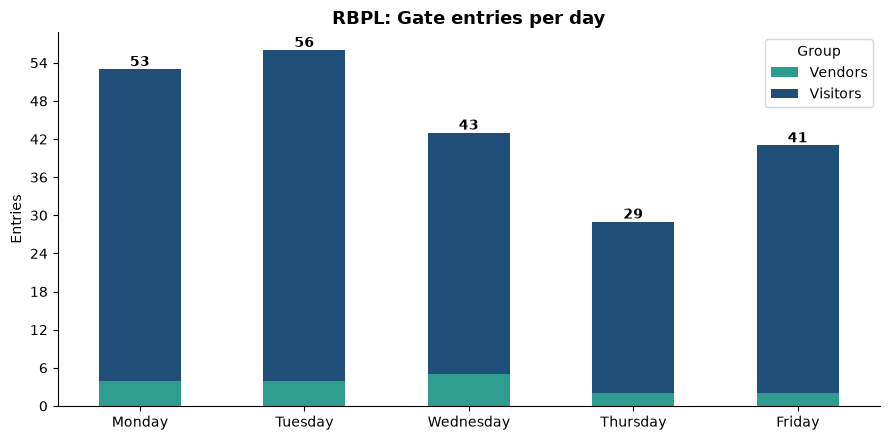

Busiest day: Tuesday (56 entries); quietest: Thursday

--- 3. Peak hours ---


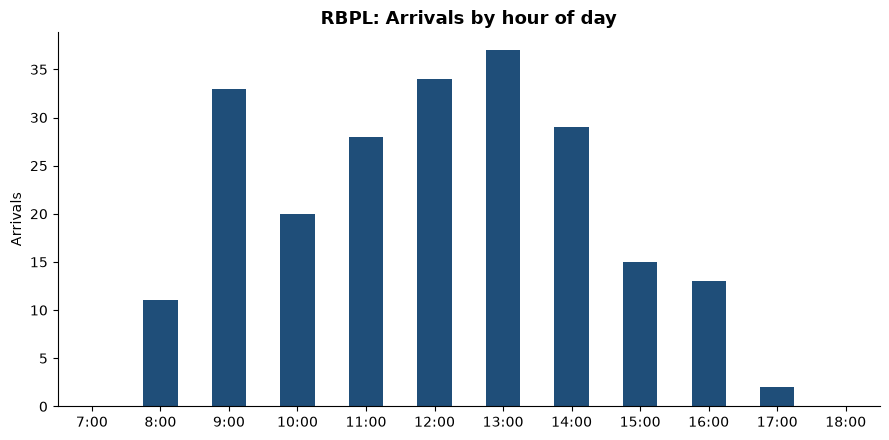

Peak hour: 13:00–14:00 (37 arrivals, 17% of all entries)


Hour,8,9,10,11,12,13,14,15,16,17
Day,,,,,,,,,,
Monday,4,7,1,9,7,9,7,4,4,1
Tuesday,2,10,9,6,10,7,8,4,0,0
Wednesday,2,5,3,8,5,12,2,3,3,0
Thursday,0,9,3,3,5,3,4,0,2,0
Friday,3,2,4,2,7,6,8,4,4,1



--- 4. Host companies ---


Group,Vendors,Visitors,Total
HostCompany,,,
Greenwich Merchant Bank,3,33,36
Sunbeth Global Concept,2,32,34
BETAGLASS,4,24,28
Red Bull Nigeria Limited,5,13,18
Sunbeth Energy,3,15,18
Optiva Capital Partners,0,16,16
Qucoon,0,14,14
GCT Group,0,10,10
POSCO,0,8,8


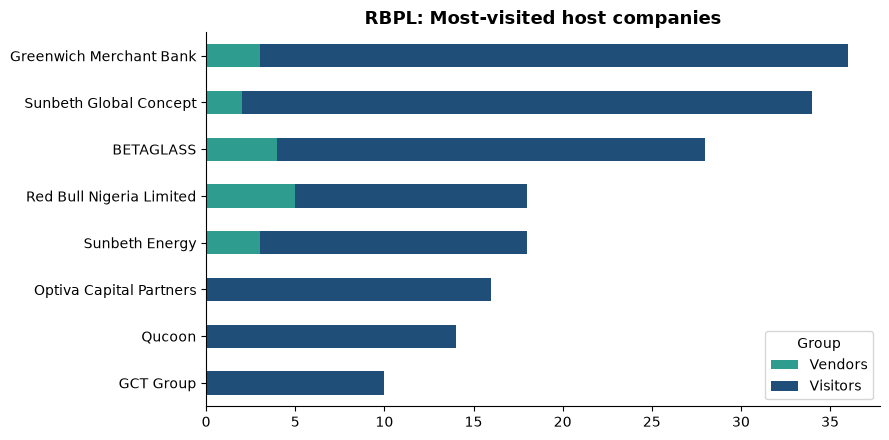

Greenwich Merchant Bank received 16% of all entries.  Entries with no host company recorded: 0

--- 5. Purpose & check-in method ---


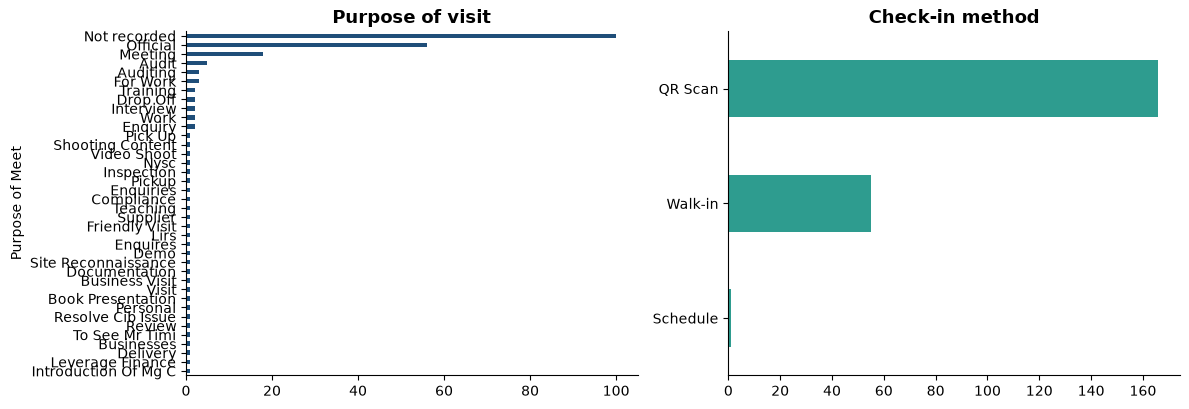

Group,Vendors,Visitors,Total
Type,,,
QR Scan,17,149,166
Walk-in,0,55,55
Schedule,0,1,1


Walk-ins (not pre-registered): 25% of entries | Purpose not recorded: 45%

--- 6. Time on premises ---
ℹ 45 entries (20%) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.
All entries:
          count   mean  median     max
Group                                 
Vendors    17.0  160.0    59.0   491.0
Visitors  203.0  146.0    64.0  1477.0


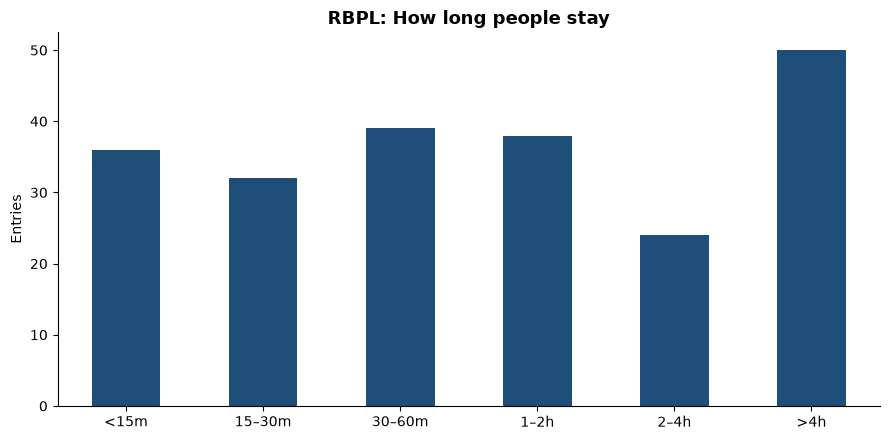


Excluding bulk sign-outs (more reliable):
          count   mean  median     max
Group                                 
Vendors    17.0  160.0    59.0   491.0
Visitors  158.0   97.0    44.0  1477.0

Stays longer than 4 hrs (28 of 51 were bulk sign-outs):


2,Group,Name,HostCompany,TimeIn,TimeOut,StayMins,BulkSignOut
138,Visitors,Akim benamara,FBIS Technology,2026-11-04 16:50:00,2026-11-05 17:27:00,1477.0,False
0,Visitors,Isaac,Sunbeth Global Concept,2026-11-02 08:07:00,2026-11-02 17:20:00,553.0,True
166,Visitors,Glory,Red Bull Nigeria Limited,2026-11-06 08:06:00,2026-11-06 17:03:00,537.0,True
50,Visitors,Onowho Ufoma,Qucoon,2026-11-03 08:46:00,2026-11-03 17:20:00,514.0,True
167,Visitors,Joseph,Red Bull Nigeria Limited,2026-11-06 08:33:00,2026-11-06 17:03:00,510.0,True
139,Visitors,Alimat,Qucoon,2026-11-05 09:00:00,2026-11-05 17:27:00,507.0,False
1,Visitors,Jimoh Olaoluwa,POSCO,2026-11-02 08:55:00,2026-11-02 17:20:00,505.0,True
102,Visitors,Jimoh Olaoluwa,POSCO,2026-11-04 08:55:00,2026-11-04 17:19:00,504.0,False
2,Visitors,Juliet,Red Bull Nigeria Limited,2026-11-02 08:57:00,2026-11-02 17:20:00,503.0,True
140,Visitors,Josiah,Qucoon,2026-11-05 09:05:00,2026-11-05 17:28:00,503.0,True



--- 7. Exceptions for follow-up ---
Records with no sign-out time (verify they left):


2,Group,Name,HostCompany,TimeIn
48,Visitors,Chisom Okonkwo,Greenwich Merchant Bank,2026-11-02 17:05:00
204,Visitors,Ope,Greenwich Merchant Bank,2026-11-06 17:06:00


Repeat visitors (same name, >1 entry this week):


,Name,Visits,Days,Group
NameKey,,,,
damilare,Damilare,4,3,Vendors
michael,Michael,4,2,Visitors
rita,Rita,3,3,Visitors
oluwaseyi,Oluwaseyi,3,3,Visitors
jimoh olaoluwa,Jimoh Olaoluwa,3,3,Visitors
amaka,Amaka,2,2,Visitors
eniola,Eniola,2,2,Visitors
emmanuel,Emmanuel,2,1,Visitors
ella,Ella,2,1,Visitors


... (4 outputs left out)


--- 8. Talking points ---
• RBPL gate recorded 222 entries this week (222 people including accompanying persons): 205 visitors, 17 vendors.
• Busiest day was Tuesday with 56 entries; peak arrival hour was 13:00–14:00 (17% of arrivals).
• Greenwich Merchant Bank was the most-visited host (16% of entries).
• Typical stay was 48 mins (average 103), excluding 45 entries signed out in bulk at closing. 51 stay(s) exceeded 4 hrs, 28 of them bulk sign-outs.
• 2 record(s) had no sign-out time – security should confirm these people left.
• 100% of entries have no government ID number captured; 29 have no category and 100 have no purpose recorded.

--- 9. Export ---
Saved: C:\Users\Moses\Downloads\gatecheck_output\RBPL
01_daily_entries.png
  02_hourly_arrivals.png
  03_host_companies.png
  04_purpose_method.png
  05_stay_duration.png
  Gatecheck_RBPL_weekly_summary.xlsx
  FCPL
⚠ Visitors: column(s) not found in this export -> ['Access Card', 'From Address', 'Persons(+)', 'Vehicle No']. Columns p

,Visitors,Vendors,All
Entries (records),89.0,21.0,110.0
Unique people,82.0,20.0,102.0
Total headcount (incl. accompanying),89.0,21.0,110.0
Avg stay (mins),103.0,97.0,102.0
Median stay (mins),86.0,62.0,85.0
Stays > 4 hrs,7.0,1.0,8.0
Bulk sign-outs (stay time unreliable),0.0,0.0,0.0
Not signed out,3.0,0.0,3.0
With laptop/iPad declared,0.0,0.0,0.0
Arrived with vehicle,2.0,1.0,3.0



--- 2. Daily traffic ---


Group,Vendors,Visitors,Total
Day,,,
Monday,2,19,21
Tuesday,7,20,27
Wednesday,7,14,21
Thursday,4,17,21
Friday,1,19,20


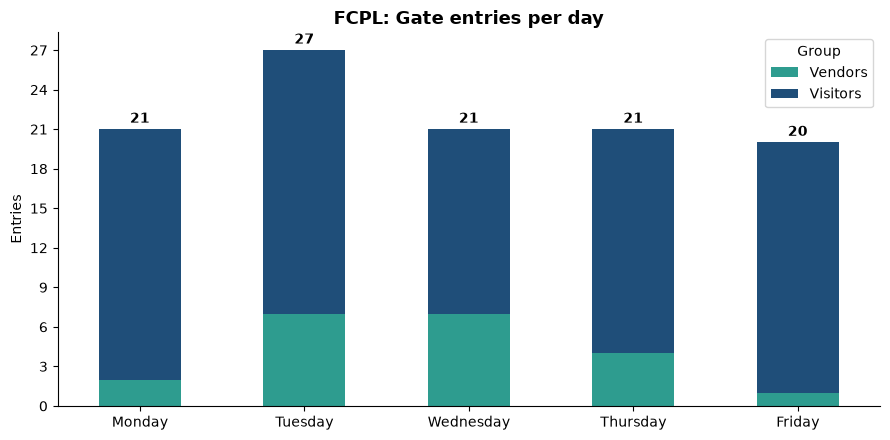

Busiest day: Tuesday (27 entries); quietest: Friday

--- 3. Peak hours ---


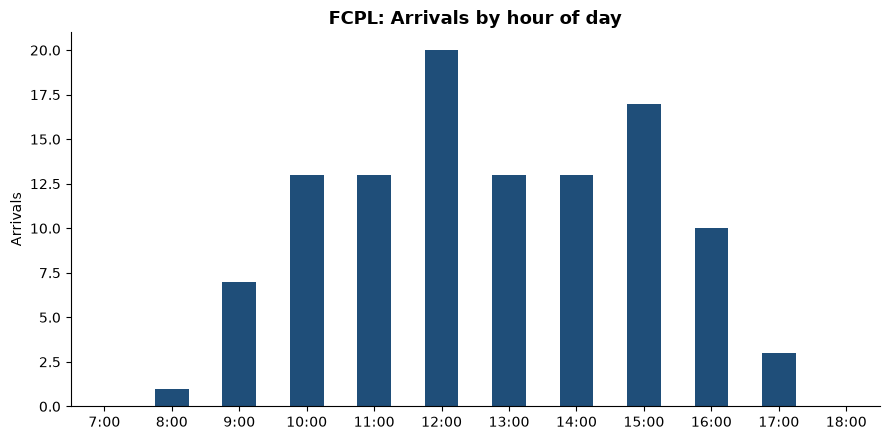

Peak hour: 12:00–13:00 (20 arrivals, 18% of all entries)


Hour,8,9,10,11,12,13,14,15,16,17
Day,,,,,,,,,,
Monday,0,2,5,1,4,1,3,1,2,2
Tuesday,0,1,2,4,6,2,4,6,2,0
Wednesday,1,4,4,4,1,4,0,3,0,0
Thursday,0,0,2,2,6,3,2,5,1,0
Friday,0,0,0,2,3,3,4,2,5,1



--- 4. Host companies ---


Group,Vendors,Visitors,Total
HostCompany,,,
03Capital Nigeria Limited,7,13,20
Greenwich Holdings Limited,4,13,17
POWERGAS,0,13,13
Greenwich Capital Limited,0,12,12
BUCCH ENERGY LIMITED,1,10,11
CHURCHGATE,4,6,10
AFRICA PLUS PARTNERS NIGERIA LIMITED,1,6,7
BlueBerryTravel,0,6,6
GTL Properties Limited,3,1,4


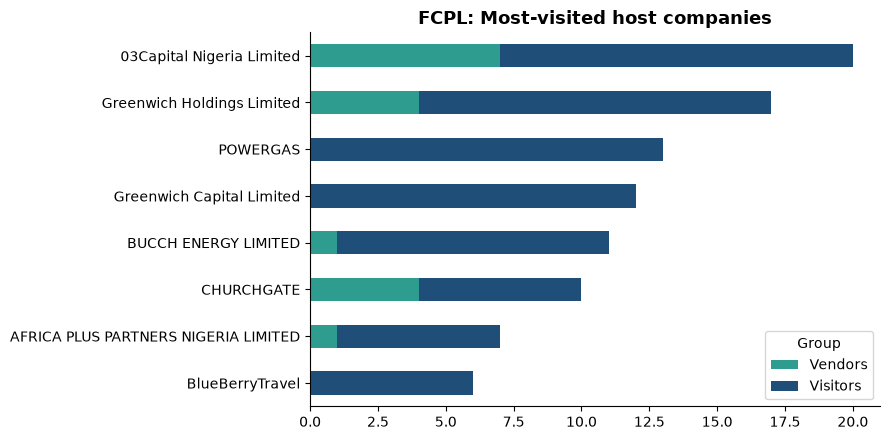

03Capital Nigeria Limited received 18% of all entries.  Entries with no host company recorded: 0

--- 5. Purpose & check-in method ---


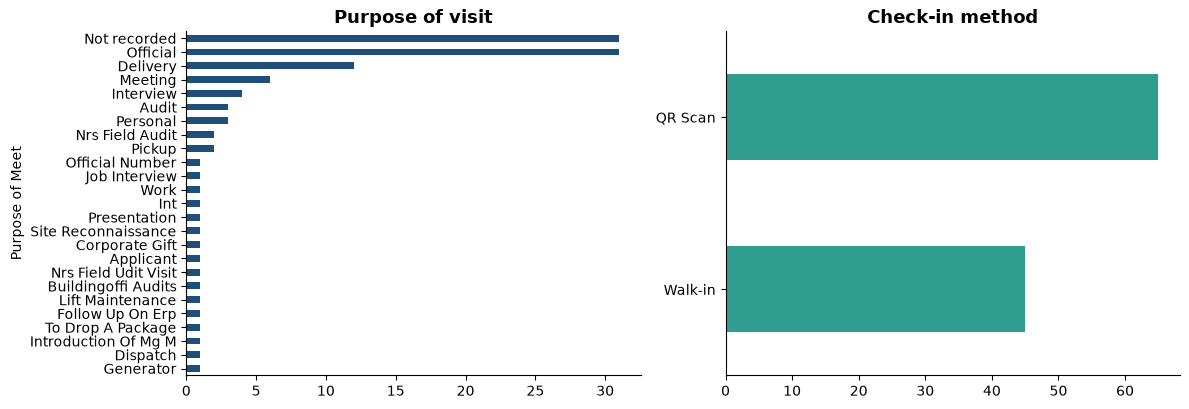

Group,Vendors,Visitors,Total
Type,,,
QR Scan,4,61,65
Walk-in,17,28,45


Walk-ins (not pre-registered): 41% of entries | Purpose not recorded: 28%

--- 6. Time on premises ---
ℹ 0 entries (0%) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.
All entries:
          count   mean  median    max
Group                                
Vendors    21.0   97.0    62.0  261.0
Visitors   86.0  103.0    86.0  400.0


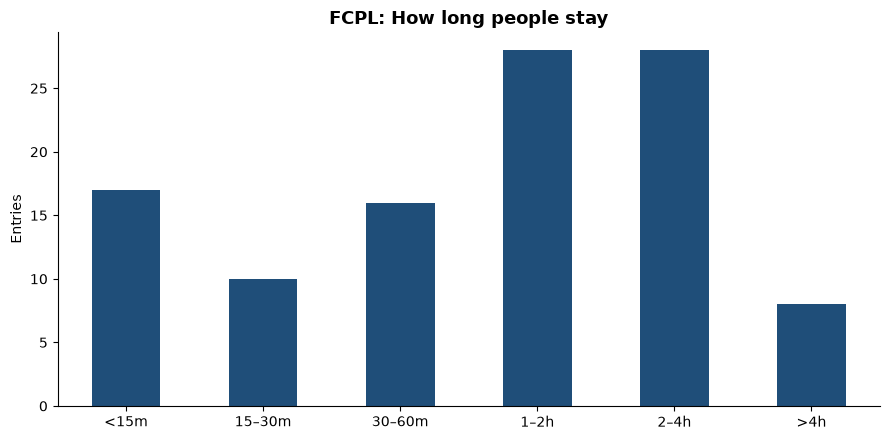


Excluding bulk sign-outs (more reliable):
          count   mean  median    max
Group                                
Vendors    21.0   97.0    62.0  261.0
Visitors   86.0  103.0    86.0  400.0

Stays longer than 4 hrs (0 of 8 were bulk sign-outs):


2,Group,Name,HostCompany,TimeIn,TimeOut,StayMins,BulkSignOut
5,Visitors,Fielami Jennifer,POWERGAS,2026-11-02 10:53:00,2026-11-02 17:33:00,400.0,False
43,Visitors,Olalowo OLATOKUN,POWERGAS,2026-11-04 10:04:00,2026-11-04 16:21:00,377.0,False
20,Visitors,Fielami Jennifer,POWERGAS,2026-11-03 10:52:00,2026-11-03 16:11:00,319.0,False
21,Visitors,OLATOKUN Olalowo,POWERGAS,2026-11-03 10:55:00,2026-11-03 16:12:00,317.0,False
47,Visitors,Raphael Mwhittington,BUCCH ENERGY LIMITED,2026-11-04 11:34:00,2026-11-04 16:21:00,287.0,False
1,Visitors,Bukunmi,03Capital Nigeria Limited,2026-11-02 09:51:00,2026-11-02 14:28:00,277.0,False
44,Visitors,Fielami Jennifer,POWERGAS,2026-11-04 10:22:00,2026-11-04 14:57:00,275.0,False
103,Vendors,Ire Jaga,CHURCHGATE,2026-11-04 13:12:00,2026-11-04 17:33:00,261.0,False



--- 7. Exceptions for follow-up ---
Records with no sign-out time (verify they left):


2,Group,Name,HostCompany,TimeIn
16,Visitors,Chisom Okonkwo,Greenwich Capital Limited,2026-11-02 16:32:00
18,Visitors,Cynthia Onuigbo,Greenwich Holdings Limited,2026-11-02 17:38:00
88,Visitors,Akinlolu Akinyele,Greenwich Holdings Limited,2026-11-06 17:28:00


Repeat visitors (same name, >1 entry this week):


,Name,Visits,Days,Group
NameKey,,,,
fielami jennifer,Fielami Jennifer,3,3,Visitors
benjamin oyom,Benjamin Oyom,2,2,Visitors
dejola lufadeju,Dejola Lufadeju,2,2,Visitors
innocent,Innocent,2,1,Visitors
mohammed,Mohammed,2,2,Visitors
olatokun olalowo,OLATOKUN Olalowo,2,2,Visitors
yakubu ataguba,Yakubu Ataguba,2,2,Vendors


Large groups (3+ accompanying):


2,Group,Name,HostCompany,Persons(+),TimeIn


Data-quality gaps:


,Records,% of entries
Category blank,100,91.0
Purpose of visit blank,31,28.0
Host company missing,0,0.0
Email not captured,67,61.0
Govt ID number not captured,110,100.0
No sign-out time,3,3.0



--- 8. Talking points ---
• FCPL gate recorded 110 entries this week (110 people including accompanying persons): 89 visitors, 21 vendors.
• Busiest day was Tuesday with 27 entries; peak arrival hour was 12:00–13:00 (18% of arrivals).
• 03Capital Nigeria Limited was the most-visited host (18% of entries).
• Typical stay was 85 mins (average 102), excluding 0 entries signed out in bulk at closing. 8 stay(s) exceeded 4 hrs, 0 of them bulk sign-outs.
• 3 record(s) had no sign-out time – security should confirm these people left.
• 100% of entries have no government ID number captured; 100 have no category and 31 have no purpose recorded.

--- 9. Export ---
Saved: C:\Users\Moses\Downloads\gatecheck_output\FCPL
01_daily_entries.png
  02_hourly_arrivals.png
  03_host_companies.png
  04_purpose_method.png
  05_stay_duration.png
  Gatecheck_FCPL_weekly_summary.xlsx

Branches completed: ['RBPL', 'FCPL']


In [29]:
results = {}
for b in BRANCHES:
    r = analyse(b)
    if r is not None: results[b] = r
print('\nBranches completed:', list(results))

## 4. Side-by-side comparison (for the COO)

In [30]:
# ---- comparison table ----
assert results, 'No branch loaded any data – check the file paths in Cell 2.'
def pct(a, b): return f'{a / b:.0%}' if b else '–'
rows = {}
for b, r in results.items():
    A, d, h = r['ALL'], r['daily'], r['hosts']
    rows[b] = {
        'Total entries': len(A),
        'Visitors': len(r['frames'].get('Visitors', [])), 'Vendors': len(r['frames'].get('Vendors', [])),
        'Total headcount (incl. accompanying)': int(A['Headcount'].sum()),
        'Unique people': A['NameKey'].nunique(),
        'Busiest day': f"{d['Total'].idxmax()} ({d['Total'].max()})",
        'Peak arrival hour': f"{r['pk']}:00–{r['pk']+1}:00",
        'Top host company': f"{h.index[0]} ({pct(h.iloc[0]['Total'], len(A))})",
        'Typical stay, mins (median, excl. bulk sign-outs)': round(r['real']['StayMins'].median()),
        'Entries signed out in bulk': r['bulk'],
        'Not signed out': int(A['StillInside'].sum()),
        'Walk-ins (% of entries)': pct((A['Type'].str.lower() == 'walk-in').sum(), len(A)),
        'Purpose not recorded': pct(A['Purpose of Meet'].isna().sum(), len(A)),
        'Email not captured': pct(A['Email'].isna().sum(), len(A)),
        'Govt ID number not captured': pct((~A['GovtIDCaptured']).sum(), len(A)),
    }
comparison = pd.DataFrame(rows)
display(comparison)

,RBPL,FCPL
Total entries,222,110
Visitors,205,89
Vendors,17,21
Total headcount (incl. accompanying),222,110
Unique people,198,102
Busiest day,Tuesday (56),Tuesday (27)
Peak arrival hour,13:00–14:00,12:00–13:00
Top host company,Greenwich Merchant Bank (16%),03Capital Nigeria Limited (18%)
"Typical stay, mins (median, excl. bulk sign-outs)",48,85
Entries signed out in bulk,45,0


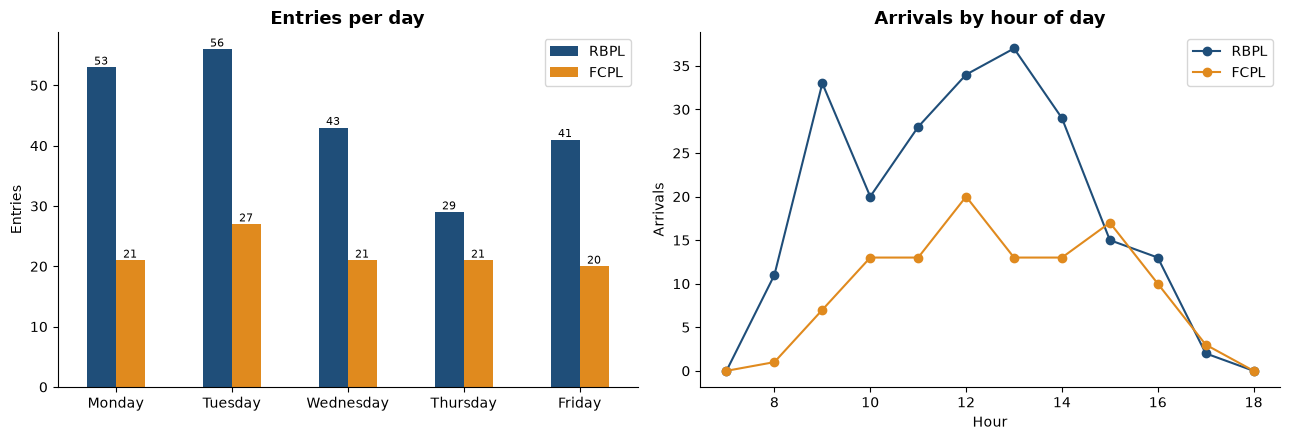

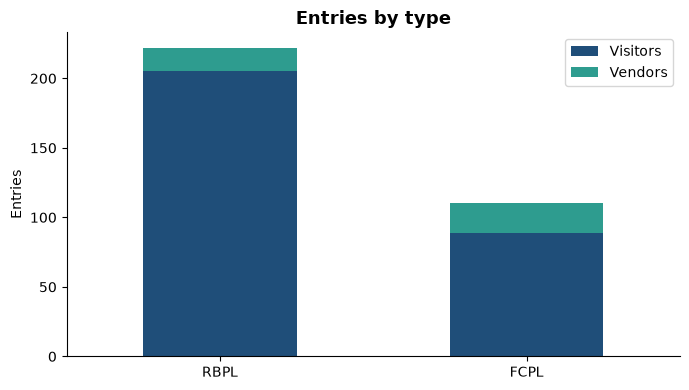

In [31]:
# ---- comparison charts (same scale for both branches) ----
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dd = pd.DataFrame({b: r['daily']['Total'] for b, r in results.items()}).reindex(day_order).fillna(0)
dd.plot(kind='bar', ax=ax[0], rot=0, color=[BRANCH_COLORS[c] for c in dd.columns]); ax[0].set_title('Entries per day'); ax[0].set_xlabel(''); ax[0].set_ylabel('Entries')
for c in ax[0].containers: ax[0].bar_label(c, fontsize=8)
hh = pd.DataFrame({b: r['hourly'] for b, r in results.items()})
hh.plot(ax=ax[1], marker='o', color=[BRANCH_COLORS[c] for c in hh.columns]); ax[1].set_title('Arrivals by hour of day'); ax[1].set_xlabel('Hour'); ax[1].set_ylabel('Arrivals')
plt.tight_layout(); plt.savefig(f'{OUTPUT_ROOT}/Comparison_daily_hourly.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
mix = pd.DataFrame({b: r['summary'].loc['Entries (records)'].drop('All') for b, r in results.items()}).T.fillna(0)
mix.plot(kind='bar', stacked=True, ax=ax, rot=0, color=[COLORS[c] for c in mix.columns]); ax.set_title('Entries by type'); ax.set_ylabel('Entries')
plt.tight_layout(); plt.savefig(f'{OUTPUT_ROOT}/Comparison_mix.png', dpi=150); plt.show()

In [32]:
# ---- comparison talking points + save ----
if len(results) == 2:
    (a, ra), (b, rb) = results.items(); na, nb_ = len(ra['ALL']), len(rb['ALL'])
    hi, lo = (a, b) if na >= nb_ else (b, a)
    if na == nb_: print(f'• Both branches recorded {na} entries.')
    else: print(f'• {hi} was busier than {lo}: {max(na, nb_)} vs {min(na, nb_)} entries ({max(na, nb_)/max(min(na, nb_), 1) - 1:.0%} more).')
    for x, r in results.items():
        print(f'• {x}: busiest day {r["daily"]["Total"].idxmax()}, peak hour {r["pk"]}:00, typical stay {r["real"]["StayMins"].median():.0f} mins, {int(r["ALL"]["StillInside"].sum())} not signed out.')
with pd.ExcelWriter(f'{OUTPUT_ROOT}/Gatecheck_comparison.xlsx') as w:
    comparison.to_excel(w, sheet_name='Comparison')
    for b, r in results.items(): r['daily'].to_excel(w, sheet_name=f'{b} daily')
print('Saved to:', os.path.abspath(OUTPUT_ROOT))

• RBPL was busier than FCPL: 222 vs 110 entries (102% more).
• RBPL: busiest day Tuesday, peak hour 13:00, typical stay 48 mins, 2 not signed out.
• FCPL: busiest day Tuesday, peak hour 12:00, typical stay 85 mins, 3 not signed out.
Saved to: C:\Users\Moses\Downloads\gatecheck_output
